# 03 — Baseline Model (Week 4)
**Goal:** train a Linear Regression as the first model, score it with R² on the test month, and record the result so later models (Weeks 5–7) have a number to beat.

Inputs come from Week 3 (`02_preprocessing_simple.ipynb`): `cleaned_sfr.csv` and its `Split` column (train = May 2025 – Apr 2026, test = May 2026).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

pd.set_option("display.float_format", "{:,.3f}".format)

TARGET = "ClosePrice"
NUMERIC = ["LivingArea", "LotSizeSquareFeet", "BedroomsTotal", "BathroomsTotalInteger",
           "YearBuilt", "GarageSpaces", "Stories", "Latitude", "Longitude"]
BINARY = ["PoolPrivateYN", "ViewYN", "FireplaceYN", "NewConstructionYN"]

## 1. Load the Week 3 output

In [2]:
df = pd.read_csv("cleaned_sfr.csv", parse_dates=["CloseDate"], dtype={"PostalCode": str})
train = df[df["Split"] == "train"].drop(columns="Split")
test = df[df["Split"] == "test"].drop(columns="Split")

print(f"Train: {train['CloseDate'].min():%b %Y} – {train['CloseDate'].max():%b %Y}, {len(train):,} sales")
print(f"Test:  {test['CloseDate'].min():%b %Y}, {len(test):,} sales")

Train: May 2025 – Apr 2026, 106,696 sales
Test:  May 2026, 11,991 sales


## 2. Same preprocessing as Week 3
`prepare()` is copied unchanged from `02_preprocessing_simple.ipynb`. It learns medians, ZIP prices, county columns and scaling from **train only**, then applies them to test.

In [3]:
ZIP_SMOOTHING = 20   # a ZIP needs ~20 sales before its own average outweighs the statewide one


def prepare(train, test):
    """Learn medians, ZIP prices, county columns and scaling from `train`; apply them to both."""
    train, test = train.copy(), test.copy()

    # 1) median fill + "was missing" flags
    medians = train[NUMERIC].median()
    for col in NUMERIC:
        if train[col].isna().any():
            train[f"{col}_missing"] = train[col].isna().astype(int)
            test[f"{col}_missing"] = test[col].isna().astype(int)
    train[NUMERIC] = train[NUMERIC].fillna(medians)
    test[NUMERIC] = test[NUMERIC].fillna(medians)

    # 2) log the skewed columns
    for col in ["LivingArea", "LotSizeSquareFeet"]:
        train[col], test[col] = np.log1p(train[col]), np.log1p(test[col])

    # 3) ZIP -> smoothed average log price (training rows only)
    log_price = np.log(train[TARGET])
    overall = log_price.mean()
    stats = log_price.groupby(train["PostalCode"]).agg(["mean", "count"])
    zip_value = (stats["count"] * stats["mean"] + ZIP_SMOOTHING * overall) / (stats["count"] + ZIP_SMOOTHING)
    train["ZipPrice"] = train["PostalCode"].map(zip_value)
    test["ZipPrice"] = test["PostalCode"].map(zip_value).fillna(overall)   # unseen ZIP -> statewide average

    # 4) county one-hot; test gets exactly the training columns (unseen county -> all zeros)
    X_train = pd.get_dummies(train.drop(columns=["ListingKey", "CloseDate", TARGET, "PostalCode"]),
                             columns=["CountyOrParish"], dtype=int)
    X_test = pd.get_dummies(test.drop(columns=["ListingKey", "CloseDate", TARGET, "PostalCode"]),
                            columns=["CountyOrParish"], dtype=int).reindex(columns=X_train.columns, fill_value=0)

    # 5) standardize the continuous columns
    scale_cols = NUMERIC + ["ZipPrice"]
    scaler = StandardScaler().fit(X_train[scale_cols])
    X_train[scale_cols] = scaler.transform(X_train[scale_cols])
    X_test[scale_cols] = scaler.transform(X_test[scale_cols])

    return X_train, X_test, np.log(train[TARGET]), test[TARGET]


def time_split(df, test_month, months_back):
    """Test = one calendar month. Train = the `months_back` months right before it."""
    month = df["CloseDate"].dt.to_period("M")
    test_month = pd.Period(test_month, "M")
    train = df[(month >= test_month - months_back) & (month < test_month)]
    test = df[month == test_month]
    return train, test

In [4]:
X_train, X_test, y_train, y_test = prepare(train, test)
print(f"X_train {X_train.shape}, X_test {X_test.shape}")

X_train (106696, 77), X_test (11991, 77)


## 3. Train the baseline
The model learns **log(price)**, then predictions are turned back into dollars with `exp`. R² is measured in dollars on the test month.

Two even simpler "models" are scored next to it, so the R² means something:
* **Guess the median:** every home gets the training median price. Anything useful must beat this.
* **Size only:** Linear Regression on living area alone. Shows how much location and the other features add.

In [5]:
def r2_dollars(model, X_tr, X_te):
    model.fit(X_tr, y_train)
    return (r2_score(np.exp(y_train), np.exp(model.predict(X_tr))),
            r2_score(y_test, np.exp(model.predict(X_te))))


median_guess = np.full(len(y_test), np.exp(y_train).median())
size_train, size_test = r2_dollars(LinearRegression(), X_train[["LivingArea"]], X_test[["LivingArea"]])

baseline = LinearRegression()
full_train, full_test = r2_dollars(baseline, X_train, X_test)

results = pd.DataFrame([
    {"model": "Guess the median", "features": 0, "train_R2": np.nan,
     "test_R2": r2_score(y_test, median_guess)},
    {"model": "Linear Regression (size only)", "features": 1, "train_R2": size_train, "test_R2": size_test},
    {"model": "Linear Regression (all features)", "features": X_train.shape[1],
     "train_R2": full_train, "test_R2": full_test},
])
results

,model,features,train_R2,test_R2
0,Guess the median,0,NaN,-0.097
1,Linear Regression (size only),1,0.307,0.293
2,Linear Regression (all features),77,0.768,0.779


**Reading the table:**
* Guessing the median scores about 0 (slightly below, because prices are skewed): that's the floor.
* Size alone explains part of the price. Adding location (ZIP price, county, coordinates) and the other features is what lifts the model.
* Train and test R² are close, so the model is **not overfitting**. A straight-line model is simple enough that its errors come from what it *can't* capture (bias), not from memorizing training homes. That's the gap Week 5's trees should close.

## 4. What the model learned
Every continuous input was standardized, so the coefficients are on a comparable scale: "change in log price for a 1-standard-deviation change in this feature". A coefficient of 0.10 means roughly **+10% price**.

In [6]:
coefs = pd.Series(baseline.coef_, index=X_train.columns)
non_county = coefs[~coefs.index.str.startswith("CountyOrParish_")]
non_county.sort_values(key=abs, ascending=False).head(12).to_frame("coefficient (log price)")

,coefficient (log price)
Latitude,-0.463
ZipPrice,0.375
Longitude,-0.230
LivingArea,0.204
NewConstructionYN,0.106
BathroomsTotalInteger,0.096
PoolPrivateYN,0.065
GarageSpaces_missing,0.059
Stories,-0.041
Stories_missing,-0.041


* **Location dominates.** Latitude, ZipPrice and Longitude are three of the top four. Latitude and longitude work together with the county columns to describe *where in California* the home is, so read them as a group, not one by one.
* **Size is next:** LivingArea is the biggest non-location feature. Being new construction, more bathrooms and a pool add a few percent each.
* **Read signs with care.** BedroomsTotal comes out slightly **negative** (about −1%): at the *same* living area, more bedrooms means smaller rooms. That's an overlap between inputs, not "bedrooms lower the price".

## 5. Where it goes wrong

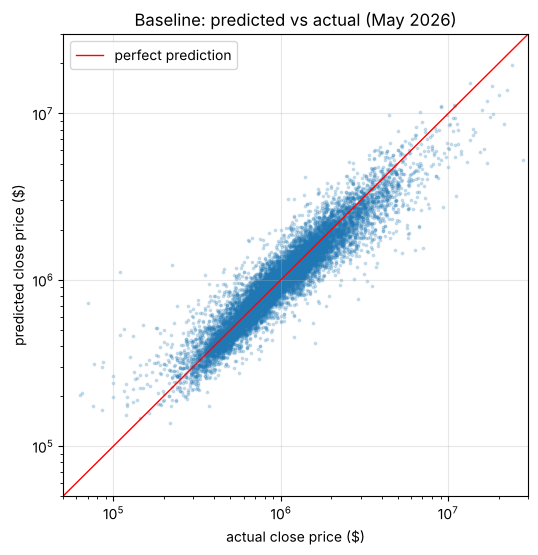

In [7]:
pred = np.exp(baseline.predict(X_test))
pct_error = np.abs(pred - y_test) / y_test

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, pred, s=3, alpha=0.2)
lims = [5e4, 3e7]
ax.plot(lims, lims, color="red", lw=1, label="perfect prediction")
ax.set(xscale="log", yscale="log", xlim=lims, ylim=lims,
       xlabel="actual close price ($)", ylabel="predicted close price ($)",
       title="Baseline: predicted vs actual (May 2026)")
ax.legend(); ax.grid(alpha=0.3); plt.show()

In [8]:
bands = pd.qcut(y_test, 5, labels=["cheapest 20%", "20–40%", "40–60%", "60–80%", "priciest 20%"])
pd.DataFrame({"actual": y_test, "pct_error": pct_error}).groupby(bands, observed=True).agg(
    sales=("actual", "size"),
    price_range=("actual", lambda s: f"${s.min():,.0f} – ${s.max():,.0f}"),
    median_pct_error=("pct_error", "median"),
)

,sales,price_range,median_pct_error
ClosePrice,,,
cheapest 20%,2411,"$62,700 – $580,000",0.114
20–40%,2387,"$580,990 – $807,500",0.107
40–60%,2432,"$808,000 – $1,125,000",0.101
60–80%,2366,"$1,127,000 – $1,685,000",0.125
priciest 20%,2395,"$1,687,500 – $28,000,000",0.172


Typical errors are about 10–12% across most of the market, but jump to about 17% for the priciest 20% of homes. Luxury prices depend on things the data barely captures (views, lot quality, finishes), and a single straight line in log space can't bend for them. Week 5's Decision Tree and Random Forest can model those bends.

## 6. Recorded baseline

In [9]:
print(f"BASELINE  Linear Regression, {X_train.shape[1]} features, trained on {len(train):,} sales "
      f"(May 2025 – Apr 2026)")
print(f"          test R² on May 2026 = {full_test:.3f}")
print(f"          median % error      = {pct_error.median():.1%}")

BASELINE  Linear Regression, 77 features, trained on 106,696 sales (May 2025 – Apr 2026)
          test R² on May 2026 = 0.779
          median % error      = 12.1%


## Summary
* **Model:** Linear Regression on log(ClosePrice), using the Week 3 features (size, lot, beds, baths, age, garage, stories, coordinates, 4 yes/no flags, county one-hot, smoothed ZIP price).
* **Split:** train May 2025 – Apr 2026, test May 2026 (from Week 3).
* **Result:** test **R² = 0.779** on May 2026, median error 12.1%. This is the number Weeks 5–7 must beat. (Guessing the median: R² ≈ −0.10. Size only: R² ≈ 0.29.)
* **Behavior:** train R² (0.768) ≈ test R² (0.779), so no overfitting. Errors grow for luxury homes, which points to non-linear models next.